# VisionGuard AI — Phase 3.4: YOLOv8 Nano Training & Evaluation

**Project:** VisionGuard AI — Infrastructure Road Damage Inspection Platform  
**Phase:** Phase 3.4 — Model Training, Validation, and Held-Out Test Evaluation  
**Target Model:** YOLOv8 Nano (`yolov8n.pt`)  
**Dataset:** RDD2022 India Subset (7,706 images: 5,356 train, 1,150 val, 1,200 test)  
**Target Classes:** `0: D00_longitudinal_crack`, `1: D10_transverse_crack`, `2: D20_alligator_crack`, `3: D40_pothole`  
**Execution Platform:** Google Colab (Cloud GPU Runtime)  

---

### Instructions for Running in Google Colab
1. **Select GPU Runtime:** Go to **Runtime** > **Change runtime type**, select **T4 GPU** under Hardware accelerator, and click **Save**.
2. **Verify Dataset:** If starting a fresh session, Step 2 will automatically restore your prepared dataset (`visionguard_dataset`) from your Google Drive backup.
3. **Execute Sequentially:** Run cells from top to bottom. Do not skip validation cells.
4. **Quarantine Test Split:** The held-out test split is strictly evaluated in Step 9 **only after** training and validation checkpoint selection are finalized.

## Step 1: Runtime & Hardware Verification

Verify GPU model, available VRAM, CUDA capability, and ephemeral disk space in the current Google Colab environment.

In [ ]:
# 1. Check GPU hardware and VRAM allocation
import os
import shutil
import subprocess
import torch

print("=== Google Colab GPU & System Diagnostics ===")
!nvidia-smi

cuda_available = torch.cuda.is_available()
print(f"\nPyTorch CUDA Available: {cuda_available}")

if cuda_available:
    gpu_name = torch.cuda.get_device_name(0)
    total_vram_gb = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)
    print(f"Active GPU Device:      {gpu_name}")
    print(f"Total Dedicated VRAM:   {total_vram_gb} GB")
    if total_vram_gb < 10.0:
        print("WARNING: VRAM is below 10 GB. If training runs Out-Of-Memory, reduce batch size to 4 or 8.")
else:
    print("\n[CRITICAL WARNING] No GPU detected! Please configure Colab:")
    print("  -> Go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU")

total_b, used_b, free_b = shutil.disk_usage('/content')
print(f"Available Disk Space:   {free_b / (1024**3):.2f} GB free in /content")

=== Google Colab GPU & System Diagnostics ===
Thu Oct 15 18:57:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-

## Step 2: Dependency Verification & Ultralytics Installation

Install and verify the official `ultralytics` package and essential computer vision libraries.

In [ ]:
# 2. Install and verify Ultralytics and dependencies
# We pin pillow to a stable version to prevent the PIL._typing import error
%pip install -q --upgrade ultralytics opencv-python "pillow>=10.0.0,<11.0.0" matplotlib pyyaml pandas

import sys
import yaml
import cv2
import PIL
import matplotlib
import torch
import ultralytics
from ultralytics import YOLO

print("=== Environment & Library Baseline ===")
print(f"Python Version:      {sys.version.split()[0]}")
print(f"PyTorch Version:     {torch.__version__}")
print(f"Ultralytics Version: {ultralytics.__version__}")
print(f"OpenCV Version:      {cv2.__version__}")
print(f"Pillow Version:      {PIL.__version__}")
print(f"Matplotlib Version:  {matplotlib.__version__}")
print("[PASSED] Dependencies verified.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 123.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 105.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 124.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 9.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
dask-cu

## Step 3: Dataset Restoration, Integrity & Split Verification

Verify that the prepared dataset exists at `/content/visionguard_dataset`.  
If starting from a new Colab session, restore the dataset from the Google Drive backup archive (`visionguard_rdd2022_india_yolo.zip`).

In [ ]:


# STEP 3: Restore and verify the prepared VisionGuard AI dataset

import os
import shutil
import zipfile
from pathlib import Path

import yaml
from google.colab import drive

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

CANONICAL_DIR = Path("/content/visionguard_dataset")
NESTED_DIR = Path("/content/content/visionguard_dataset")

DRIVE_BACKUP = Path(
    "/content/drive/MyDrive/VisionGuard_Artifacts/"
    "visionguard_rdd2022_india_yolo.zip"
)
LOCAL_BACKUP = Path("/content/visionguard_rdd2022_india_yolo.zip")

EXPECTED_CLASSES = [
    "D00_longitudinal_crack",
    "D10_transverse_crack",
    "D20_alligator_crack",
    "D40_pothole",
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


# --------------------------------------------------
# 2. Find a valid existing dataset
# --------------------------------------------------

def is_dataset_root(root):
    """Check whether root contains the expected YOLO structure."""
    return (
        (root / "data.yaml").is_file()
        and all(
            (root / "images" / split).is_dir()
            for split in ("train", "val", "test")
        )
        and all(
            (root / "labels" / split).is_dir()
            for split in ("train", "val", "test")
        )
    )


DATASET_DIR = None

for candidate in (CANONICAL_DIR, NESTED_DIR):
    if is_dataset_root(candidate):
        DATASET_DIR = candidate
        print(f"[FOUND] Valid dataset structure: {DATASET_DIR}")
        break


# --------------------------------------------------
# 3. Restore from Google Drive if needed
# --------------------------------------------------

if DATASET_DIR is None:
    print("No complete dataset found at the expected paths.")

    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    else:
        print("Google Drive is already mounted.")

    if DRIVE_BACKUP.is_file():
        BACKUP_PATH = DRIVE_BACKUP
    elif LOCAL_BACKUP.is_file():
        BACKUP_PATH = LOCAL_BACKUP
    else:
        raise FileNotFoundError(
            "Dataset ZIP was not found in Google Drive or /content."
        )

    print(f"Checking backup: {BACKUP_PATH}")

    # Inspect the archive before extracting it.
    with zipfile.ZipFile(BACKUP_PATH, "r") as zf:
        bad_member = zf.testzip()

        if bad_member is not None:
            raise RuntimeError(
                f"ZIP integrity check failed at: {bad_member}"
            )

        yaml_members = [
            name for name in zf.namelist()
            if Path(name).name.lower() == "data.yaml"
        ]

        if not yaml_members:
            raise FileNotFoundError(
                "No data.yaml found inside the dataset ZIP."
            )

        # Prefer the YAML belonging to the prepared dataset.
        preferred = [
            name for name in yaml_members
            if "visionguard_dataset" in name.replace("\\", "/").lower()
        ]
        yaml_member = preferred[0] if preferred else yaml_members[0]

        dataset_prefix = str(Path(yaml_member).parent)
        print(f"Dataset YAML inside ZIP: {yaml_member}")

        temp_dir = Path("/content/visionguard_restore_tmp")

        if temp_dir.exists():
            shutil.rmtree(temp_dir)

        temp_dir.mkdir(parents=True, exist_ok=True)

        print("Extracting backup...")
        zf.extractall(temp_dir)

    extracted_yaml = temp_dir / yaml_member

    if not extracted_yaml.is_file():
        raise FileNotFoundError(
            f"YAML was not found after extraction: {extracted_yaml}"
        )

    extracted_root = extracted_yaml.parent

    if not all(
        (extracted_root / "images" / split).is_dir()
        for split in ("train", "val", "test")
    ):
        raise FileNotFoundError(
            "The extracted YAML folder does not contain all expected "
            "images/train, images/val and images/test folders. "
            "Inspect the ZIP's directory structure before continuing."
        )

    if not all(
        (extracted_root / "labels" / split).is_dir()
        for split in ("train", "val", "test")
    ):
        raise FileNotFoundError(
            "The extracted dataset is missing one or more labels folders."
        )

    # Restore into the canonical location without overwriting any existing
    # dataset directory.
    if CANONICAL_DIR.exists():
        raise FileExistsError(
            f"{CANONICAL_DIR} already exists but is incomplete. "
            "Inspect it before replacing or deleting anything."
        )

    shutil.copytree(extracted_root, CANONICAL_DIR)
    shutil.rmtree(temp_dir)

    DATASET_DIR = CANONICAL_DIR

    print(f"[RESTORED] Dataset copied to: {DATASET_DIR}")


# --------------------------------------------------
# 4. Load and validate data.yaml
# --------------------------------------------------

YAML_PATH = DATASET_DIR / "data.yaml"

assert YAML_PATH.is_file(), f"Missing YAML: {YAML_PATH}"

with open(YAML_PATH, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

assert isinstance(data_config, dict), "data.yaml must contain a YAML mapping."

names = data_config.get("names")

if isinstance(names, dict):
    names = [
        names[i] if i in names else names[str(i)]
        for i in range(len(names))
    ]

assert names == EXPECTED_CLASSES, (
    f"Unexpected class names or order.\n"
    f"Expected: {EXPECTED_CLASSES}\n"
    f"Found:    {names}"
)

# Use the actual restored dataset root, avoiding stale paths from another
# extraction location.
data_config["path"] = str(DATASET_DIR)
data_config["train"] = "images/train"
data_config["val"] = "images/val"
data_config["test"] = "images/test"

with open(YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("\n=== Verified Dataset Configuration ===")
print(yaml.safe_dump(data_config, sort_keys=False))


# --------------------------------------------------
# 5. Verify all image and label directories
# --------------------------------------------------

split_images = {}
split_labels = {}

for split in ("train", "val", "test"):
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    assert image_dir.is_dir(), f"Missing image directory: {image_dir}"
    assert label_dir.is_dir(), f"Missing label directory: {label_dir}"

    image_files = {
        p.stem for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    }

    label_files = {
        p.stem for p in label_dir.iterdir()
        if p.is_file() and p.suffix.lower() == ".txt"
    }

    assert image_files, f"{split} images directory is empty."

    # Every image should have a corresponding label file.
    missing_labels = image_files - label_files
    orphan_labels = label_files - image_files

    assert not missing_labels, (
        f"{split}: {len(missing_labels)} images have no label file. "
        f"Examples: {list(sorted(missing_labels))[:5]}"
    )
    assert not orphan_labels, (
        f"{split}: {len(orphan_labels)} label files have no image. "
        f"Examples: {list(sorted(orphan_labels))[:5]}"
    )

    split_images[split] = image_files
    split_labels[split] = label_files

    print(
        f"{split}: {len(image_files):,} images | "
        f"{len(label_files):,} matching labels"
    )


# --------------------------------------------------
# 6. Verify filename disjointness between splits
# --------------------------------------------------

assert not (split_images["train"] & split_images["val"]), (
    "Overlapping image filenames between train and validation."
)
assert not (split_images["train"] & split_images["test"]), (
    "Overlapping image filenames between train and test."
)
assert not (split_images["val"] & split_images["test"]), (
    "Overlapping image filenames between validation and test."
)


# --------------------------------------------------
# 7. Verify YOLO label syntax and coordinate bounds
# --------------------------------------------------

for split in ("train", "val", "test"):
    label_dir = DATASET_DIR / "labels" / split

    for label_path in label_dir.glob("*.txt"):
        with open(label_path, "r", encoding="utf-8") as f:
            for line_number, line in enumerate(f, start=1):
                parts = line.split()

                if not parts:
                    continue

                assert len(parts) == 5, (
                    f"Invalid YOLO label format: {label_path}, "
                    f"line {line_number}"
                )

                class_id = int(parts[0])
                coords = [float(v) for v in parts[1:]]

                assert 0 <= class_id < 4, (
                    f"Invalid class ID in {label_path}, line {line_number}"
                )
                assert all(0.0 <= value <= 1.0 for value in coords), (
                    f"Coordinates outside [0,1] in {label_path}, "
                    f"line {line_number}"
                )
                assert coords[2] > 0 and coords[3] > 0, (
                    f"Invalid box dimensions in {label_path}, "
                    f"line {line_number}"
                )

print("\n[PASSED] Dataset paths, class mapping, labels, and split filenames verified.")
print("Training has NOT been started by this cell.")
print(f"Use this dataset YAML for training: {YAML_PATH}")


[FOUND] Valid dataset structure: /content/content/visionguard_dataset

=== Verified Dataset Configuration ===
path: /content/content/visionguard_dataset
train: images/train
val: images/val
test: images/test
names:
  0: D00_longitudinal_crack
  1: D10_transverse_crack
  2: D20_alligator_crack
  3: D40_pothole

train: 5,356 images | 5,356 matching labels
val: 1,150 images | 1,150 matching labels
test: 1,200 images | 1,200 matching labels

[PASSED] Dataset paths, class mapping, labels, and split filenames verified.
Training has NOT been started by this cell.
Use this dataset YAML for training: /content/content/visionguard_dataset/data.yaml


## Step 4: Class Imbalance Audit (Pre-Training Distribution)

Audit instance tallies across the training split to establish baseline expectations for each damage category, with special attention to `D10` (transverse cracks) scarcity.

In [ ]:
# 4. Detailed class distribution audit across train split
from collections import defaultdict

train_lbl_dir = os.path.join(DATASET_DIR, 'labels', 'train')
class_counts = defaultdict(int)
image_counts = defaultdict(int)
background_images = 0

for lbl_file in os.listdir(train_lbl_dir):
    if not lbl_file.endswith('.txt'): continue
    path = os.path.join(train_lbl_dir, lbl_file)
    with open(path, 'r') as f:
        lines = f.readlines()

    if len(lines) == 0:
        background_images += 1
    else:
        seen_in_img = set()
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cid = int(parts[0])
                class_counts[cid] += 1
                seen_in_img.add(cid)
        for cid in seen_in_img:
            image_counts[cid] += 1

class_names = data_config['names']
total_objects = sum(class_counts.values())

print("=== Training Split Distress Distribution Audit ===")
print(f"Total Training Images:     {len(os.listdir(train_lbl_dir)):,}")
print(f"Images with Damage:       {len(os.listdir(train_lbl_dir)) - background_images:,}")
print(f"Sound / Background Images: {background_images:,}")
print(f"Total Bounding Boxes:     {total_objects:,}\n")

print(f"{'Class ID':<10} | {'Class Name':<25} | {'Instances':<12} | {'% Share':<10} | {'Images':<10}")
print("-" * 75)
for cid in sorted(class_names.keys()):
    cname = class_names[cid]
    count = class_counts[cid]
    pct = (count / total_objects * 100) if total_objects > 0 else 0
    n_imgs = image_counts[cid]
    print(f"{cid:<10} | {cname:<25} | {count:<12,} | {pct:>6.2f}%    | {n_imgs:<10,}")
print("-" * 75)

# Explicit notice on class imbalance
print("\n[CRITICAL NOTE ON CLASS IMBALANCE]:")
print(" - Potholes (D40) and Alligator cracks (D20) comprise ~76% of all training instances.")
print(" - Transverse cracks (D10) comprise <1.5% of instances. Its recall will be naturally constrained.")
print(" - We will evaluate each class independently to avoid masking D10 performance behind overall mAP.")

=== Training Split Distress Distribution Audit ===
Total Training Images:     5,356
Images with Damage:       2,257
Sound / Background Images: 3,099
Total Bounding Boxes:     4,762

Class ID   | Class Name                | Instances    | % Share    | Images    
---------------------------------------------------------------------------
0          | D00_longitudinal_crack    | 1,050        |  22.05%    | 760       
1          | D10_transverse_crack      | 44           |   0.92%    | 41        
2          | D20_alligator_crack       | 1,436        |  30.16%    | 1,258     
3          | D40_pothole               | 2,232        |  46.87%    | 1,066     
---------------------------------------------------------------------------

[CRITICAL NOTE ON CLASS IMBALANCE]:
 - Potholes (D40) and Alligator cracks (D20) comprise ~76% of all training instances.
 - Transverse cracks (D10) comprise <1.5% of instances. Its recall will be naturally constrained.
 - We will evaluate each class independently 

## Step 5: Model Initialization & Configuration

Initialize YOLOv8 Nano (`yolov8n.pt`) with pretrained weights for transfer learning, configure hyperparameter settings (`imgsz=640`, `batch=8`, `epochs=30`, `seed=42`, `patience=10`), and prepare experiment logging directories.

In [ ]:
# 5. Initialize model and set hyperparameters
from ultralytics import YOLO

EXPERIMENT_PROJECT = '/content/visionguard_runs'
EXPERIMENT_NAME = 'yolov8n_rdd_india_exp1'

os.makedirs(EXPERIMENT_PROJECT, exist_ok=True)

print("Initializing YOLOv8 Nano baseline...")
model = YOLO('yolov8n.pt')

# Documented Training Configuration
TRAINING_CONFIG = {
    'data': YAML_PATH,
    'epochs': 30,             # Training budget
    'imgsz': 640,             # Standard resolution
    'batch': 8,               # Memory-safe batch size for Colab T4
    'patience': 10,           # Early stopping patience
    'seed': 42,               # Exact reproducibility
    'device': 0 if torch.cuda.is_available() else 'cpu',
    'workers': 2,
    'project': EXPERIMENT_PROJECT,
    'name': EXPERIMENT_NAME,
    'exist_ok': True,
    'verbose': True,
    'plots': True,
    'save': True,
    'val': True               # Validate every epoch for checkpoint selection
}

print("\n=== Planned Training Hyperparameters ===")
for k, v in TRAINING_CONFIG.items():
    print(f"  {k:<12}: {v}")

Initializing YOLOv8 Nano baseline...

=== Planned Training Hyperparameters ===
  data        : /content/content/visionguard_dataset/data.yaml
  epochs      : 30
  imgsz       : 640
  batch       : 8
  patience    : 10
  seed        : 42
  device      : 0
  workers     : 2
  project     : /content/visionguard_runs
  name        : yolov8n_rdd_india_exp1
  exist_ok    : True
  verbose     : True
  plots       : True
  save        : True
  val         : True


## Step 6: Training Execution

Execute training on the training split while monitoring loss convergence and validation metrics. The validation set is used for periodic evaluation and best-checkpoint selection (`best.pt`).

In [ ]:
# 6. Execute YOLOv8 Nano training
import time

start_time = time.time()
print(f"Starting YOLOv8 Nano training at {time.strftime('%Y-%m-%d %H:%M:%S')}...")
print("This process typically takes 30–50 minutes on a Tesla T4 GPU.\n")

train_results = model.train(**TRAINING_CONFIG)

elapsed_min = (time.time() - start_time) / 60.0
print(f"\n[COMPLETED] Training finished in {elapsed_min:.2f} minutes.")

RUN_DIR = os.path.join(EXPERIMENT_PROJECT, EXPERIMENT_NAME)
BEST_WEIGHTS_PATH = os.path.join(RUN_DIR, 'weights', 'best.pt')
LAST_WEIGHTS_PATH = os.path.join(RUN_DIR, 'weights', 'last.pt')

assert os.path.exists(BEST_WEIGHTS_PATH), f"Checkpoint not found at {BEST_WEIGHTS_PATH}!"
print(f"Best model weights saved at: {BEST_WEIGHTS_PATH} ({round(os.path.getsize(BEST_WEIGHTS_PATH) / 1e6, 2)} MB)")

Starting YOLOv8 Nano training at 2026-10-15 19:03:19...
This process typically takes 30–50 minutes on a Tesla T4 GPU.

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/content/visionguard_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=

Exception in thread Thread-14 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

       1/30      1.01G      2.479       32.5      2.433          7        640: 0% ──────────── 1/670 1.4it/s 2.6s<8:10

Exception in thread Thread-15 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

       1/30      1.01G      2.671      35.69      2.516         11        640: 0% ──────────── 2/670 2.2it/s 2.8s<4:59

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ──────────── 3/72 1.8it/s 1.2s<37.7s

Exception in thread Thread-22 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 6% ╸─────────── 5/72 2.8it/s 1.9s<23.9s

Exception in thread Thread-26 (plot_images):
Traceback (most recent call last):
Exception in thread Thread-27 (plot_images):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.1

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 72/72 6.5it/s 11.1s
                   all       1150        973      0.554      0.291      0.294      0.122
D00_longitudinal_crack        175        248      0.346      0.173      0.201     0.0816
  D10_transverse_crack          8         12          1          0     0.0887     0.0108
   D20_alligator_crack        237        281      0.457      0.566      0.524      0.256
           D40_pothole        226        432      0.412      0.427      0.364      0.142
Speed: 0.5ms preprocess, 3.1ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/visionguard_runs/yolov8n_rdd_india_exp1

[COMPLETED] Training finished in 46.50 minutes.
Best model weights saved at: /content/visionguard_runs/yolov8n_rdd_india_exp1/weights/best.pt (6.51 MB)


## Step 7: Validation Performance & Loss Curve Diagnostics

Inspect the generated training and validation loss curves, mAP progression, and confusion matrix from the completed training run.

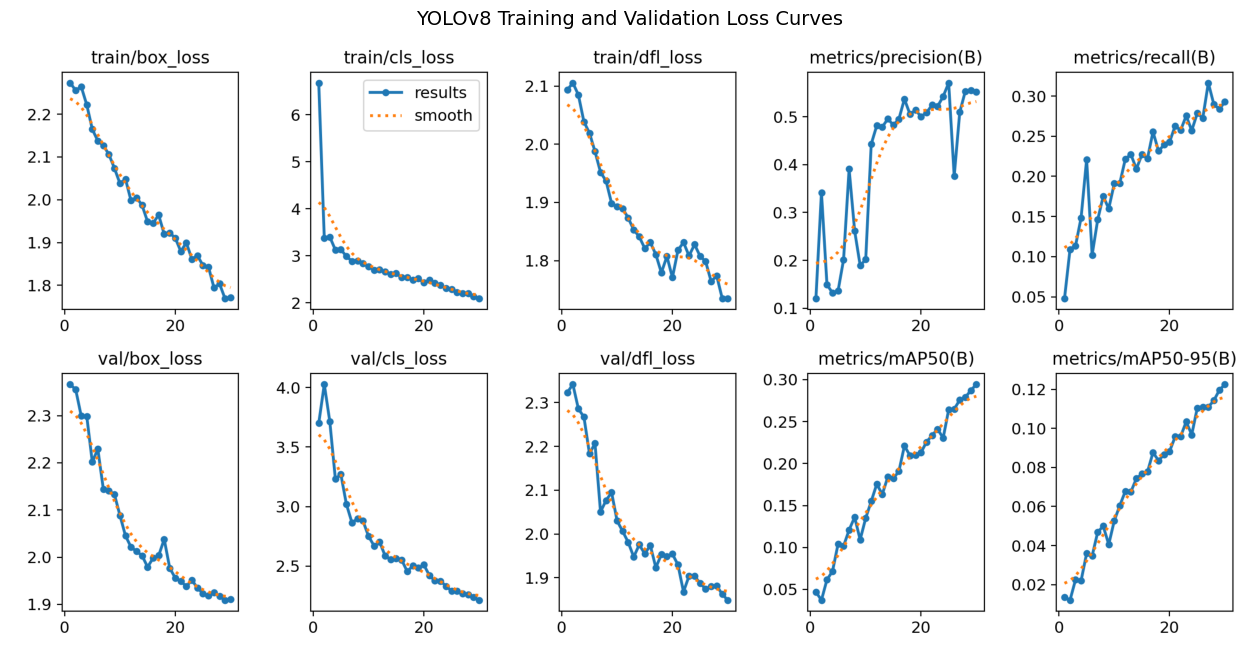

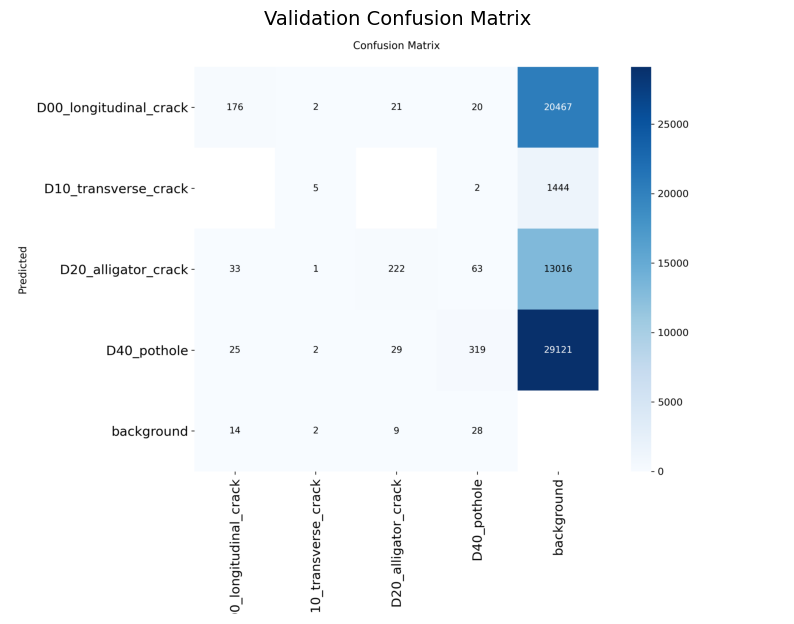

In [ ]:
# 7. Render training curves and validation diagnostics
import matplotlib.pyplot as plt
from PIL import Image

results_png = os.path.join(RUN_DIR, 'results.png')
confusion_matrix_png = os.path.join(RUN_DIR, 'confusion_matrix.png')

if os.path.exists(results_png):
    plt.figure(figsize=(16, 10))
    plt.imshow(Image.open(results_png))
    plt.title("YOLOv8 Training and Validation Loss Curves", fontsize=14)
    plt.axis('off')
    plt.show()
else:
    print("results.png not found.")

if os.path.exists(confusion_matrix_png):
    plt.figure(figsize=(10, 10))
    plt.imshow(Image.open(confusion_matrix_png))
    plt.title("Validation Confusion Matrix", fontsize=14)
    plt.axis('off')
    plt.show()
else:
    print("confusion_matrix.png not found.")

## Step 8: Validation Metrics & Class-Wise Performance Analysis

Run formal validation of `best.pt` on the validation set, extracting precision, recall, mAP@0.5, and mAP@0.5:0.95 across each individual damage class.

In [ ]:
# 8. Formal validation evaluation of best checkpoint
best_model = YOLO(BEST_WEIGHTS_PATH)

print("Running validation evaluation on validation split...")
val_metrics = best_model.val(
    data=YAML_PATH,
    split='val',
    imgsz=640,
    batch=8,
    conf=0.25,
    iou=0.6,
    project=EXPERIMENT_PROJECT,
    name='validation_eval',
    exist_ok=True
)

print("\n" + "="*75)
print("           VALIDATION SPLIT EVALUATION REPORT (best.pt)")
print("="*75)
print(f"Mean Precision:     {val_metrics.box.mp:.4f}")
print(f"Mean Recall:        {val_metrics.box.mr:.4f}")
print(f"mAP@0.5:            {val_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95:       {val_metrics.box.map:.4f}")
print("-"*75)
print(f"{'Class ID':<10} | {'Class Name':<25} | {'Precision':<12} | {'Recall':<10} | {'mAP@0.5':<10}")
print("-"*75)

for i, cid in enumerate(sorted(class_names.keys())):
    cname = class_names[cid]
    p = val_metrics.box.p[i] if i < len(val_metrics.box.p) else 0.0
    r = val_metrics.box.r[i] if i < len(val_metrics.box.r) else 0.0
    ap50 = val_metrics.box.ap50[i] if i < len(val_metrics.box.ap50) else 0.0
    print(f"{cid:<10} | {cname:<25} | {p:<12.4f} | {r:<10.4f} | {ap50:<10.4f}")
print("="*75)

Running validation evaluation on validation split...
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1634.4±397.9 MB/s, size: 58.6 KB)
val: Scanning /content/content/visionguard_dataset/labels/val.cache... 1150 images, 675 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1150/1150 344.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 2/144 2.6it/s 0.5s<54.0s

Exception in thread Thread-31 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 4/144 3.2it/s 1.2s<44.1s

Exception in thread Thread-35 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 144/144 12.8it/s 11.3s
                   all       1150        973       0.45      0.223      0.176     0.0794
D00_longitudinal_crack        175        248      0.558      0.117     0.0809     0.0353
  D10_transverse_crack          8         12          0          0          0          0
   D20_alligator_crack        237        281      0.656      0.488        0.4      0.198
           D40_pothole        226        432      0.588      0.287      0.224     0.0845
Speed: 1.4ms preprocess, 5.3ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /content/visionguard_runs/validation_eval

           VALIDATION SPLIT EVALUATION REPORT (best.pt)
Mean Precision:     0.4502
Mean Recall:        0.2229
mAP@0.5:            0.1763
mAP@0.5:0.95:       0.0794
---------------------------------------------------------------------------
Class ID   | Class Name                | P

## Step 9: Final Evaluation on the Held-Out Test Set

> [!IMPORTANT]
> **Strict Protocol:** The held-out test set (`1,200 images`) is evaluated **only now**, after model weights and hyperparameters are frozen. It was never seen during training or checkpoint selection.

In [ ]:
# 9. Formal evaluation on held-out test split
print("Running final evaluation on quarantined held-out TEST split...")
test_metrics = best_model.val(
    data=YAML_PATH,
    split='test',
    imgsz=640,
    batch=8,
    conf=0.25,
    iou=0.6,
    project=EXPERIMENT_PROJECT,
    name='test_eval',
    exist_ok=True
)

print("\n" + "="*75)
print("           HELD-OUT TEST SET EVALUATION REPORT (best.pt)")
print("="*75)
print(f"Mean Precision:     {test_metrics.box.mp:.4f}")
print(f"Mean Recall:        {test_metrics.box.mr:.4f}")
print(f"mAP@0.5:            {test_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95:       {test_metrics.box.map:.4f}")
print("-"*75)
print(f"{'Class ID':<10} | {'Class Name':<25} | {'Precision':<12} | {'Recall':<10} | {'mAP@0.5':<10}")
print("-"*75)

for i, cid in enumerate(sorted(class_names.keys())):
    cname = class_names[cid]
    p = test_metrics.box.p[i] if i < len(test_metrics.box.p) else 0.0
    r = test_metrics.box.r[i] if i < len(test_metrics.box.r) else 0.0
    ap50 = test_metrics.box.ap50[i] if i < len(test_metrics.box.ap50) else 0.0
    print(f"{cid:<10} | {cname:<25} | {p:<12.4f} | {r:<10.4f} | {ap50:<10.4f}")
print("="*75)

Running final evaluation on quarantined held-out TEST split...
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1639.0±495.9 MB/s, size: 70.0 KB)
val: Scanning /content/content/visionguard_dataset/labels/test... 1200 images, 709 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1200/1200 2.1Kit/s 0.6s
val: New cache created: /content/content/visionguard_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 2/150 1.7it/s 0.6s<1:28

Exception in thread Thread-42 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 3/150 2.9it/s 0.8s<50.7s

Exception in thread Thread-43 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 4/150 3.1it/s 1.1s<46.7s

Exception in thread Thread-46 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 3% ──────────── 5/150 3.5it/s 1.3s<41.5s

Exception in thread Thread-45 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py", line 1064, in plot_images
    annotator.im.save(fname)  # save
    ~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2588, in save
    See :py:meth:`~PIL.Image.Image.tell`.
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py", line 813, in _save
    ImageFile._save(im, fp, [("jpeg", (0, 0) + im.size, 0, rawmode)], bufsize)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 646, 

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 150/150 12.7it/s 11.8s
                   all       1200       1096      0.462      0.247      0.203      0.088
D00_longitudinal_crack        174        257      0.623      0.167      0.139     0.0547
  D10_transverse_crack         11         12          0          0          0          0
   D20_alligator_crack        263        304      0.615      0.553       0.48      0.223
           D40_pothole        238        523      0.609      0.268      0.191     0.0745
Speed: 1.4ms preprocess, 5.3ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /content/visionguard_runs/test_eval

           HELD-OUT TEST SET EVALUATION REPORT (best.pt)
Mean Precision:     0.4618
Mean Recall:        0.2469
mAP@0.5:            0.2026
mAP@0.5:0.95:       0.0880
---------------------------------------------------------------------------
Class ID   | Class Name                | Precis

## Step 10: Qualitative Predictions Visualization on Test Images

Run inference on sample test images and render predicted bounding boxes, defect labels, and detection confidence scores.

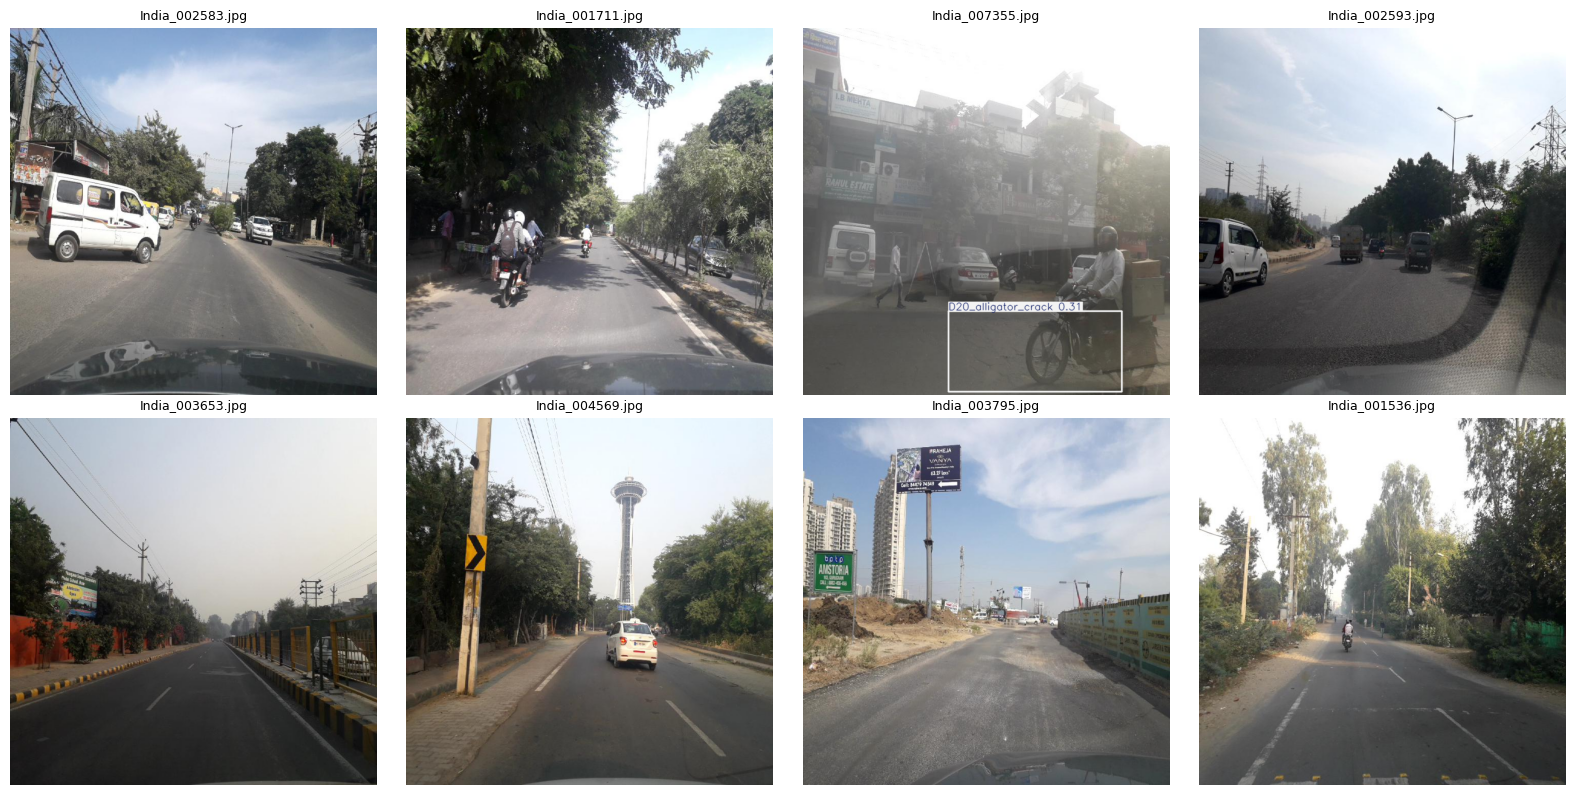

In [ ]:
# 10. Visualize predictions on sample test images
test_img_dir = os.path.join(DATASET_DIR, 'images', 'test')
sample_test_files = [f for f in os.listdir(test_img_dir) if f.lower().endswith(('.jpg', '.png'))][:8]

plt.figure(figsize=(16, 8))
for i, s_file in enumerate(sample_test_files):
    img_path = os.path.join(test_img_dir, s_file)
    preds = best_model.predict(source=img_path, conf=0.25, verbose=False)[0]
    annotated_img = preds.plot()
    annotated_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 4, i + 1)
    plt.imshow(annotated_rgb)
    plt.title(s_file, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Step 11: Model Checkpoint Export & Google Drive Backup

Save the best checkpoint (`best.pt`), export evaluation summaries to JSON, and back up the weights to Google Drive.

In [ ]:
# 11. Save model weights and summary to Google Drive
import json

DRIVE_ARTIFACTS_DIR = '/content/drive/MyDrive/VisionGuard_Artifacts'
os.makedirs(DRIVE_ARTIFACTS_DIR, exist_ok=True)

# Export summary JSON
summary = {
    'model': 'YOLOv8 Nano (yolov8n.pt)',
    'dataset': 'RDD2022 India Subset',
    'epochs_trained': 30,
    'image_size': 640,
    'batch_size': 8,
    'validation_metrics': {
        'mean_precision': float(val_metrics.box.mp),
        'mean_recall': float(val_metrics.box.mr),
        'mAP_50': float(val_metrics.box.map50),
        'mAP_50_95': float(val_metrics.box.map)
    },
    'test_metrics': {
        'mean_precision': float(test_metrics.box.mp),
        'mean_recall': float(test_metrics.box.mr),
        'mAP_50': float(test_metrics.box.map50),
        'mAP_50_95': float(test_metrics.box.map)
    },
    'classes': data_config['names']
}

summary_json_path = os.path.join(RUN_DIR, 'experiment_summary.json')
with open(summary_json_path, 'w') as f:
    json.dump(summary, f, indent=2)

# Copy best.pt to Drive
drive_best_pt = os.path.join(DRIVE_ARTIFACTS_DIR, 'best.pt')
drive_summary = os.path.join(DRIVE_ARTIFACTS_DIR, 'experiment_summary.json')

shutil.copyfile(BEST_WEIGHTS_PATH, drive_best_pt)
shutil.copyfile(summary_json_path, drive_summary)

print(f"[SUCCESS] Best weights backed up to Drive: {drive_best_pt} ({round(os.path.getsize(drive_best_pt) / 1e6, 2)} MB)")
print(f"[SUCCESS] Summary backed up to Drive:      {drive_summary}")

print("\n--- HOW TO DOWNLOAD TO LOCAL LAPTOP FOR PHASE 4 FLASK INTEGRATION ---")
print("Option A: Open Google Drive in your browser, navigate to 'VisionGuard_Artifacts', and download 'best.pt'.")
print("Option B: Run in Colab: from google.colab import files; files.download(BEST_WEIGHTS_PATH)")
print("Place the downloaded 'best.pt' file into your local project at: visionGuard/ai/models/best.pt")

[SUCCESS] Best weights backed up to Drive: /content/drive/MyDrive/VisionGuard_Artifacts/best.pt (6.51 MB)
[SUCCESS] Summary backed up to Drive:      /content/drive/MyDrive/VisionGuard_Artifacts/experiment_summary.json

--- HOW TO DOWNLOAD TO LOCAL LAPTOP FOR PHASE 4 FLASK INTEGRATION ---
Option A: Open Google Drive in your browser, navigate to 'VisionGuard_Artifacts', and download 'best.pt'.
Option B: Run in Colab: from google.colab import files; files.download(BEST_WEIGHTS_PATH)
Place the downloaded 'best.pt' file into your local project at: visionGuard/ai/models/best.pt


## Step 12: Phase 3.4 Completion & Engineering Guardrails Notice

> [!CAUTION]
> **Engineering Guardrails:**  
> 1. A 2D bounding box localizes distress instances and calculates pixel dimensions, but **does not measure true physical crack width** without camera calibration and ground-plane homography.  
> 2. Statistical model confidence measures detection certainty, **not structural safety or severity**.  
> 3. Transverse crack (`D10`) metrics reflect real-world data scarcity in the Indian road network.